# HBC组合组与原模型空间类别图

读取主库内已复制的control和combined结果，不训练、不依赖库外实验目录。原论文训练和默认结果不变。

并列显示Ground Truth、原模型及组合组，标注实际ARI、轮次和seed；重点区域放大图的黑色空心圈标记真实区域点位。颜色匹配仅用于展示，不修改标签。

输出：`results/hbc_combined/<profile>/figures/<best或final>/seed_<seed>/`，同时在Notebook内显示。已生成的五seed峰值图也已复制到这里。峰值是ARI辅助选轮，末轮为第500轮。


In [1]:
from pathlib import Path
import sys, importlib.util
ROOT = next((q for p in [Path.cwd(), *Path.cwd().parents]
             for q in [p, p / "sidmgf_final"]
             if (q / "config/hbc_combined_figures.json").is_file()), None)
if ROOT is None: raise FileNotFoundError("请在ST或sidmgf_final目录内打开Notebook")
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
spec=importlib.util.spec_from_file_location("hbc_combined_plotting",ROOT / "src/hbc_combined_figures.py")
plotter=importlib.util.module_from_spec(spec)
spec.loader.exec_module(plotter)
print("主库目录：",ROOT)


主库目录： c:\Users\吴浪\Desktop\ST\sidmgf_final


In [2]:
PROFILE = "refined"
SEEDS = [0, 1, 2, 3, 42]  # 先快速查看可改为[0]，不要只挑胜出的seed用于结论
ENDPOINTS = ["best"]       # 查看末轮改为["final"]；两者都看用["best", "final"]
ZOOM_REGIONS = ["DCIS/LCIS_2", "DCIS/LCIS_5", "IDC_3"]  # 不需放大可改为[]


In [3]:
metrics, images = plotter.generate(PROFILE, SEEDS, ENDPOINTS, ZOOM_REGIONS)
from IPython.display import display
# 先显示真实轮次与ARI，再展示对应图。
display(metrics[["profile","seed","arm","endpoint","epoch","ARI","NMI"]])


Saved: C:\Users\吴浪\Desktop\ST\sidmgf_final\results\hbc_combined\refined\figures\best\seed_0
Saved: C:\Users\吴浪\Desktop\ST\sidmgf_final\results\hbc_combined\refined\figures\best\seed_1
Saved: C:\Users\吴浪\Desktop\ST\sidmgf_final\results\hbc_combined\refined\figures\best\seed_2
Saved: C:\Users\吴浪\Desktop\ST\sidmgf_final\results\hbc_combined\refined\figures\best\seed_3
Saved: C:\Users\吴浪\Desktop\ST\sidmgf_final\results\hbc_combined\refined\figures\best\seed_42


,profile,seed,arm,endpoint,epoch,ARI,NMI
0,refined,0,control,best,349,0.698231,0.681847
1,refined,0,combined,best,320,0.707086,0.692766
2,refined,1,control,best,196,0.686405,0.678750
3,refined,1,combined,best,439,0.705552,0.700715
4,refined,2,control,best,188,0.695703,0.692359
5,refined,2,combined,best,354,0.681297,0.688761
6,refined,3,control,best,187,0.685123,0.684665
7,refined,3,combined,best,435,0.731955,0.715935
8,refined,42,control,best,350,0.713797,0.709136
9,refined,42,combined,best,300,0.726604,0.705044


**results\hbc_combined\refined\figures\best\seed_0\spatial_comparison.png**

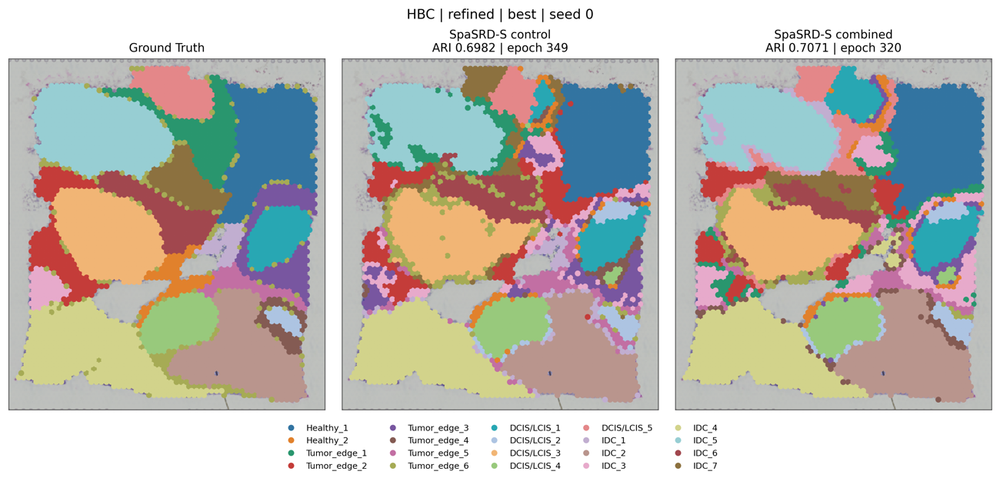

**results\hbc_combined\refined\figures\best\seed_0\region_zoom.png**

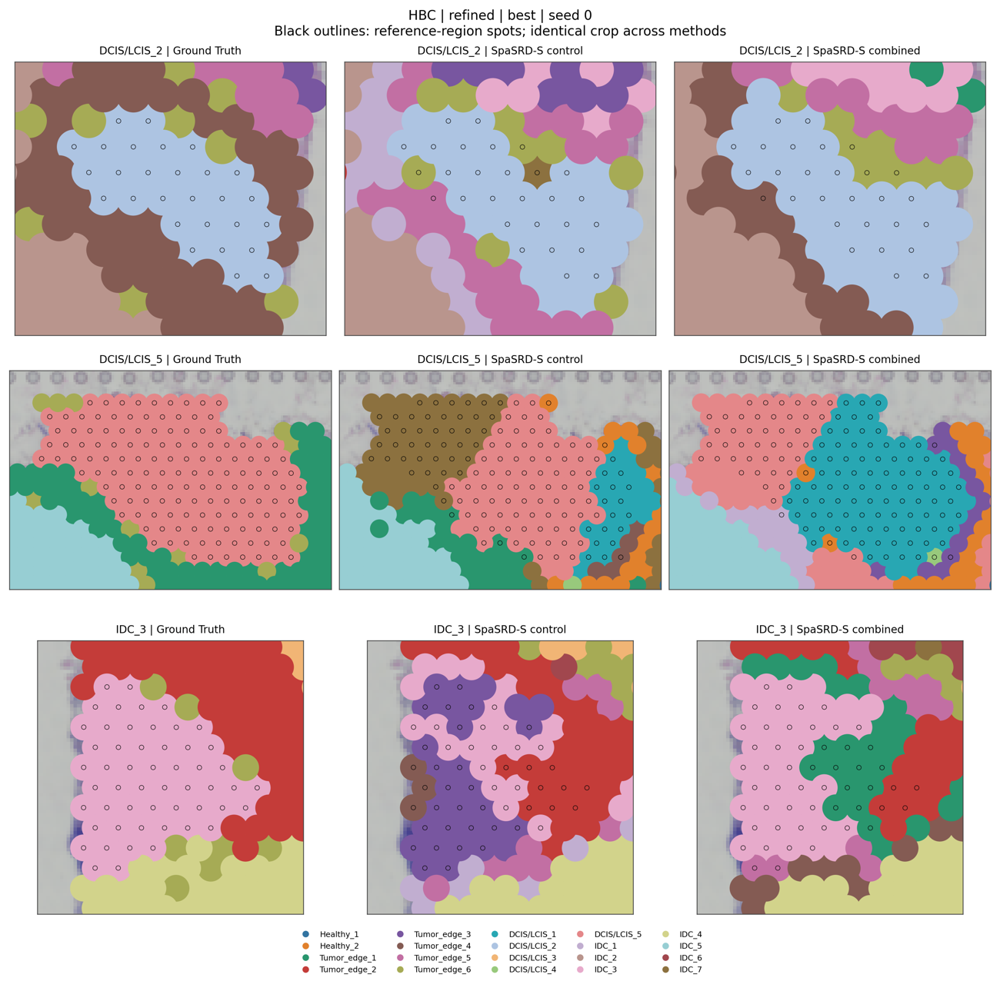

**results\hbc_combined\refined\figures\best\seed_1\spatial_comparison.png**

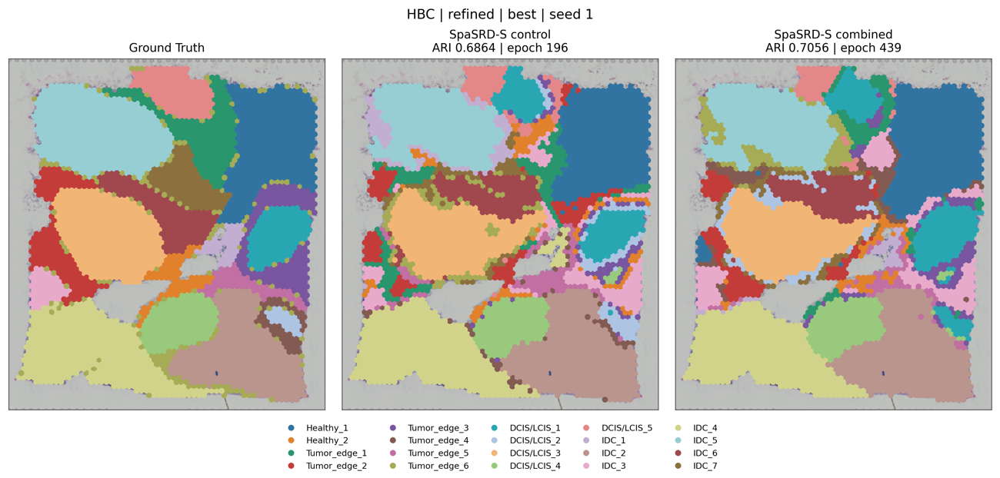

**results\hbc_combined\refined\figures\best\seed_1\region_zoom.png**

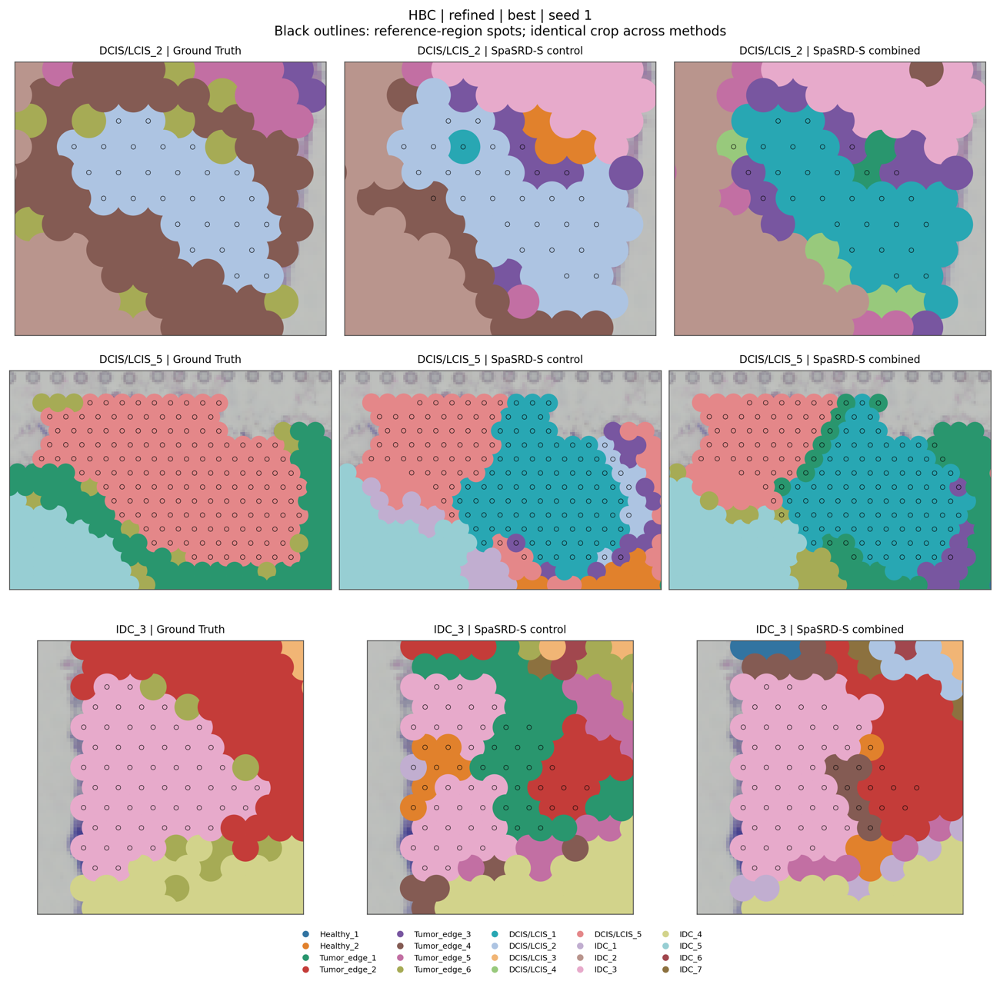

**results\hbc_combined\refined\figures\best\seed_2\spatial_comparison.png**

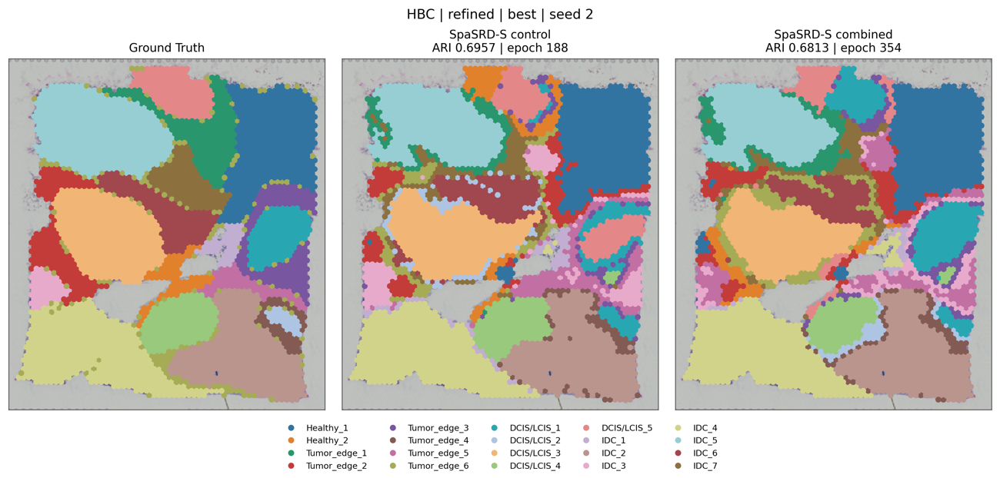

**results\hbc_combined\refined\figures\best\seed_2\region_zoom.png**

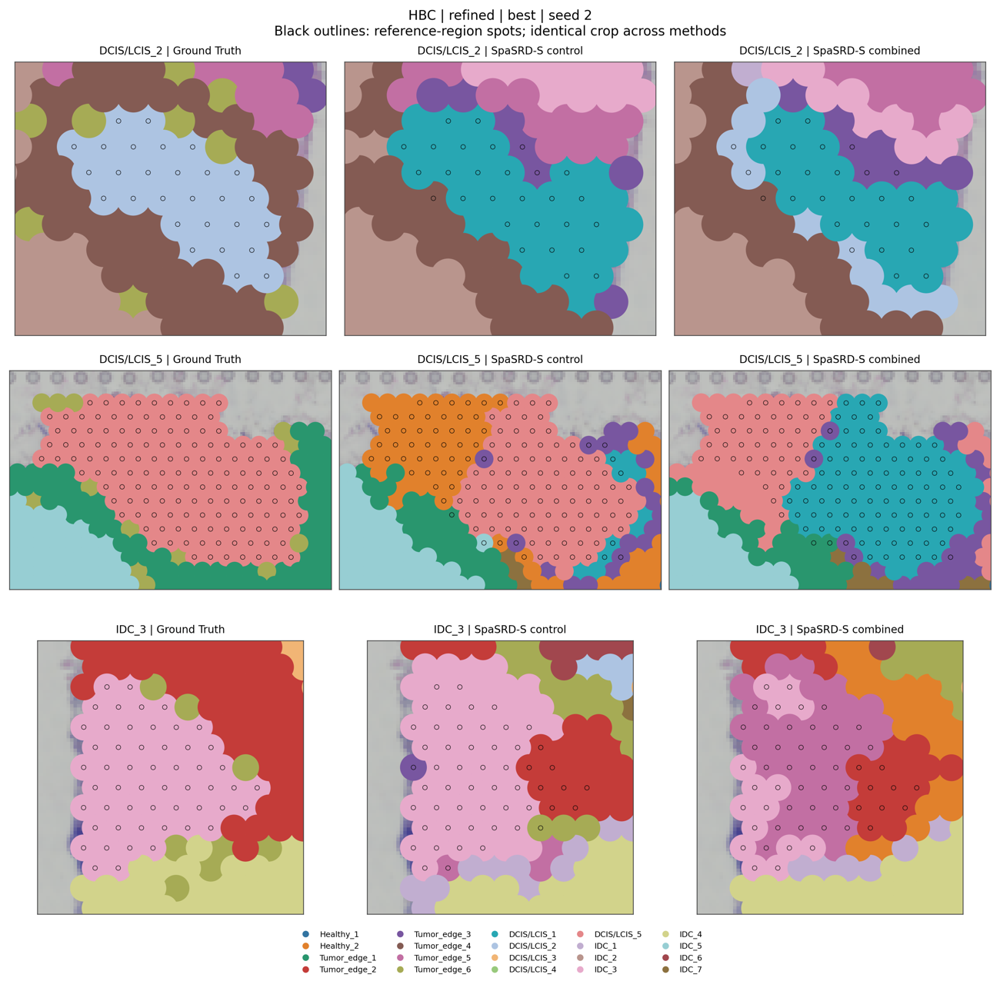

**results\hbc_combined\refined\figures\best\seed_3\spatial_comparison.png**

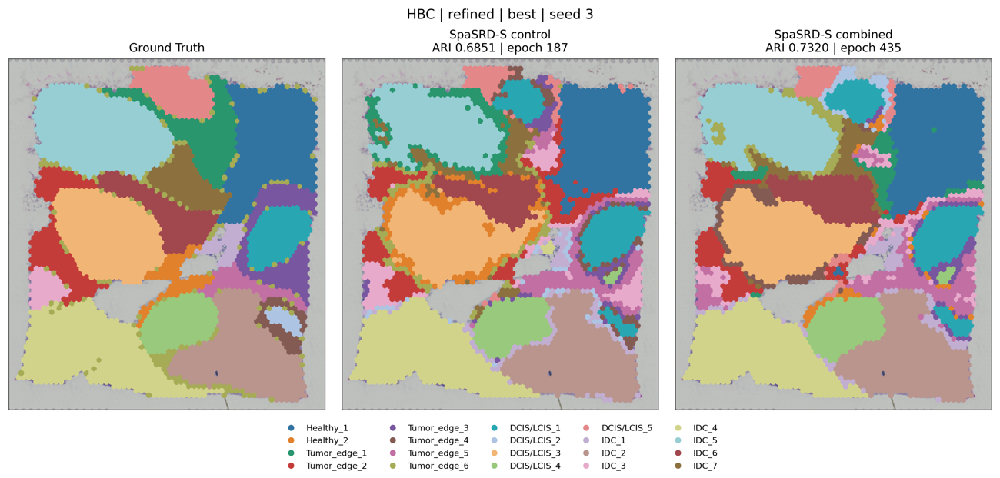

**results\hbc_combined\refined\figures\best\seed_3\region_zoom.png**

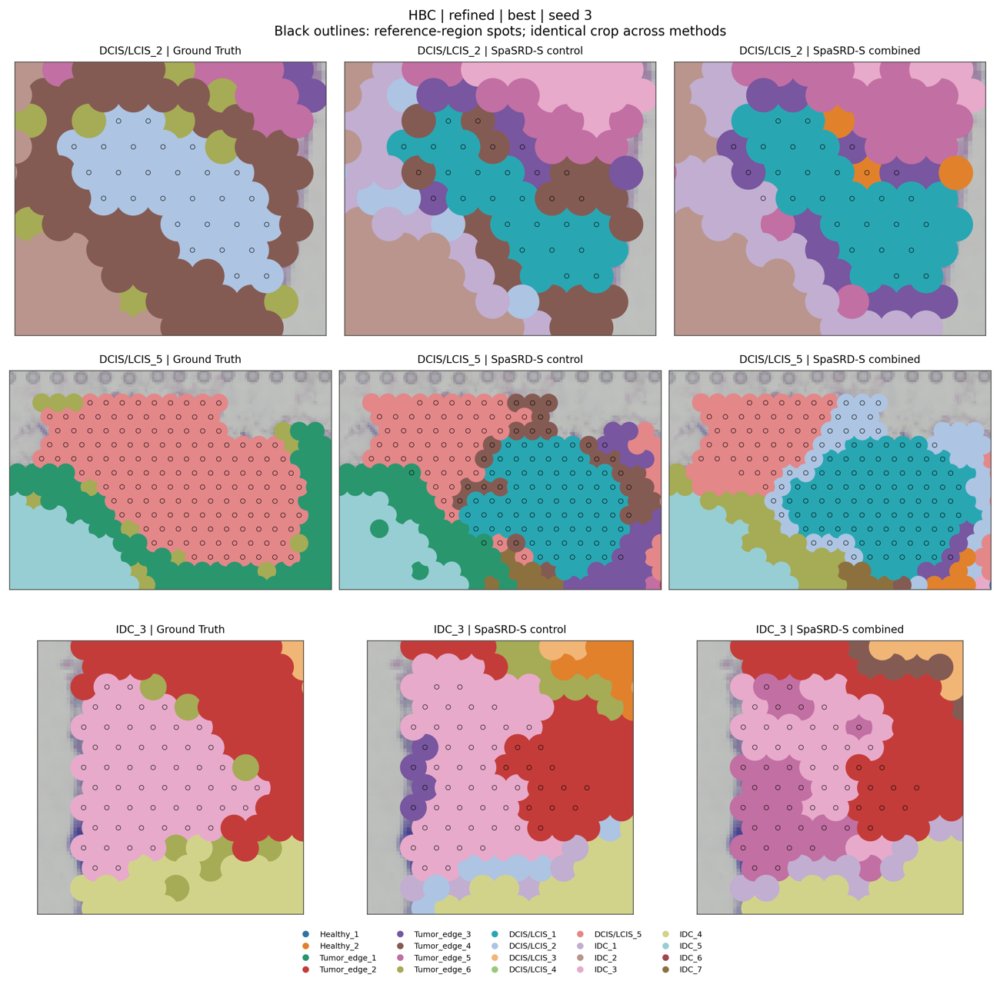

**results\hbc_combined\refined\figures\best\seed_42\spatial_comparison.png**

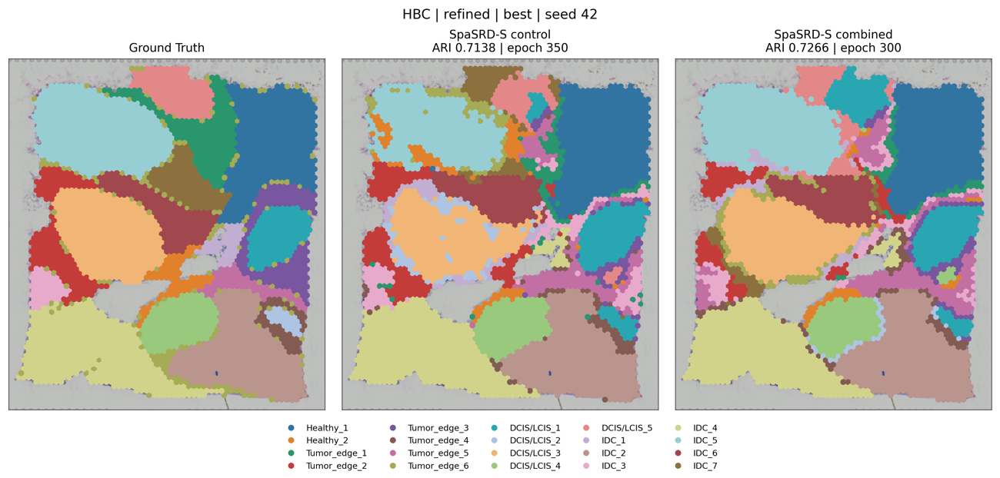

**results\hbc_combined\refined\figures\best\seed_42\region_zoom.png**

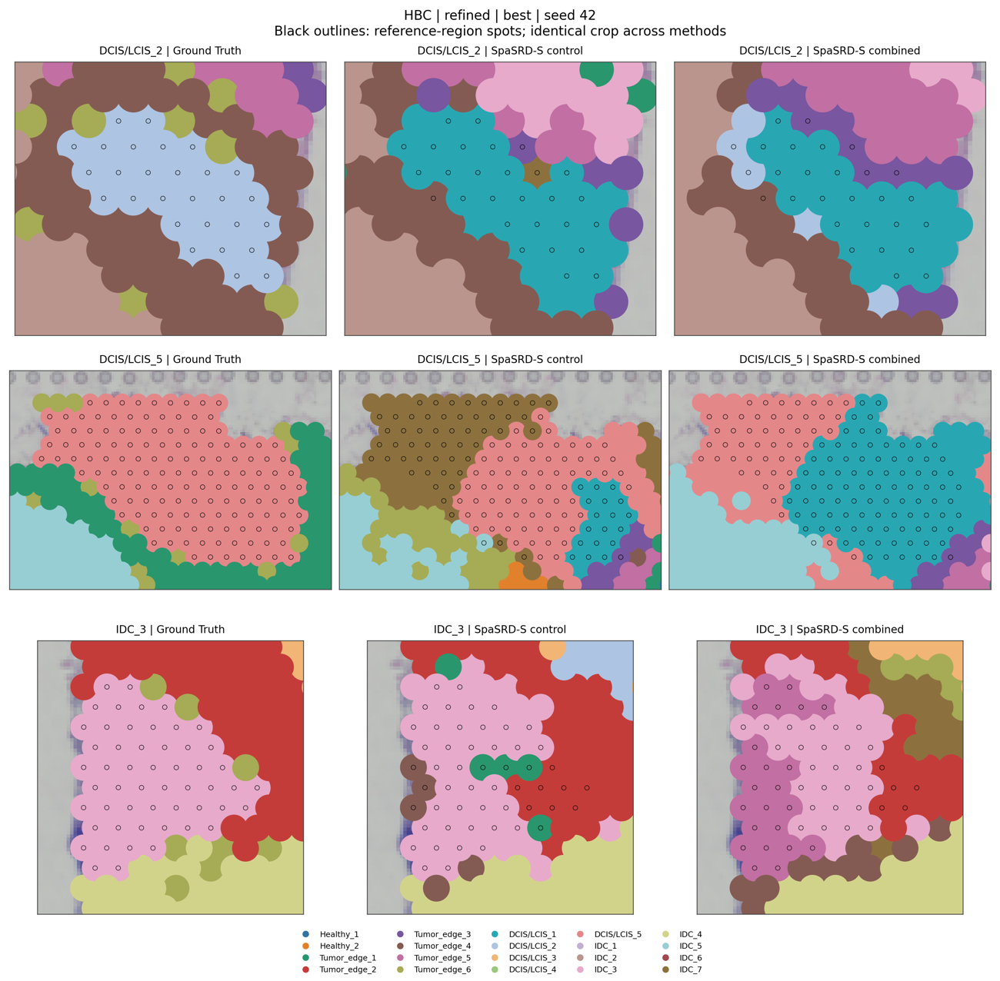

所有高清图与逐点来源保存在： c:\Users\吴浪\Desktop\ST\sidmgf_final\results\hbc_combined\refined\figures


: 

In [ ]:
from IPython.display import display, Markdown
from PIL import Image
for path in images:
    display(Markdown("**" + str(path.relative_to(ROOT)) + "**"))
    with Image.open(path) as im:
        preview=im.convert("RGB")
        preview.thumbnail((1300,1300))
        display(preview)
print("所有高清图与逐点来源保存在：", ROOT / "results/hbc_combined" / PROFILE / "figures")
